# Matplotlib with Seaborn Revision Cheat Sheet for AI/ML

Seaborn provides statistical plotting on top of Matplotlib. Use Seaborn for data-aware plots and Matplotlib methods for final control.

**Argument policy:** Every argument used in each demonstrated call is explained in adjacent comments.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("Seaborn version:", sns.__version__)


Seaborn version: 0.13.2


## 1. Theme, context, and palette


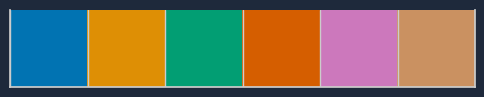

In [2]:
sns.set_theme(
    context="notebook",           # context: scaling preset: paper, notebook, talk, or poster
    style="whitegrid",            # style: axes appearance: darkgrid, whitegrid, dark, white, ticks
    palette="deep",               # palette: default color cycle name/list
    font="sans-serif",            # font: font family
    font_scale=1.0,               # font_scale: multiplies context font sizes
    color_codes=True,             # color_codes: remap shorthand colors to current palette
    rc={"axes.spines.top":False}   # rc: Matplotlib rcParam overrides
)
sns.set_context("notebook", font_scale=1.0, rc=None)
# context: scaling preset; font_scale: extra text scaling; rc: context-specific rc overrides
palette = sns.color_palette(palette="colorblind", n_colors=6, desat=1.0)
# palette: palette name/specification; n_colors: returned colors; desat: saturation multiplier
sns.palplot(palette)              # pal: color sequence displayed as horizontal swatches
plt.show()


## 2. Sample tidy dataset


In [3]:
rng=np.random.default_rng(42)
df=pd.DataFrame({
    "feature":rng.normal(size=200),
    "target":rng.normal(size=200),
    "category":rng.choice(["A","B","C"],size=200),
    "group":rng.choice(["train","validation"],size=200),
    "score":rng.normal(75,10,size=200)
})
df["target"] = 1.8*df["feature"] + df["target"]
print(df.head())


    feature    target category       group      score
0  0.304717  0.886065        B  validation  58.482409
1 -1.039984 -0.464490        A       train  62.189308
2  0.750451  1.441397        C       train  70.763934
3  0.940565  2.336955        C  validation  69.794116
4 -1.951035 -5.562035        C  validation  83.126013


## 3. scatterplot


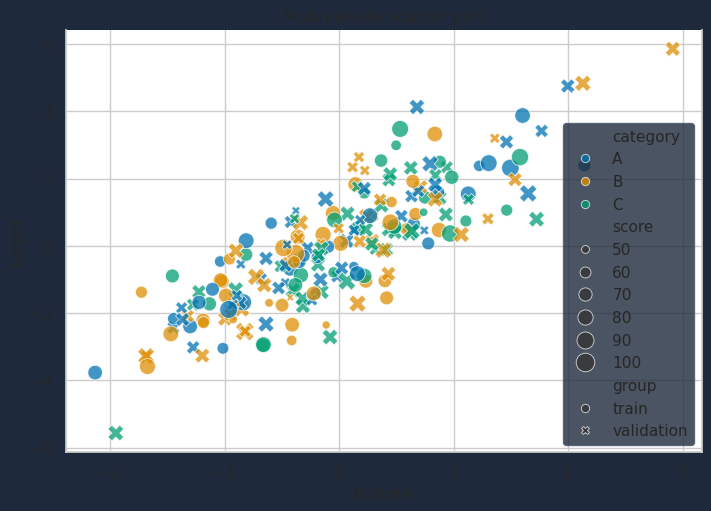

In [4]:
fig,ax=plt.subplots(figsize=(7,5),layout="constrained")
sns.scatterplot(
    data=df,                      # data: tidy DataFrame containing named variables
    x="feature",                  # x: column mapped to x position
    y="target",                   # y: column mapped to y position
    hue="category",               # hue: column mapped to color
    size="score",                 # size: column mapped to marker area
    style="group",                # style: column mapped to marker shape
    palette="colorblind",         # palette: hue color mapping
    hue_order=["A","B","C"],    # hue_order: explicit category/color order
    hue_norm=None,                # hue_norm: numeric hue normalization
    sizes=(30,180),               # sizes: min/max area for numeric size mapping
    size_order=None,              # size_order: explicit order for categorical sizes
    size_norm=None,               # size_norm: numeric size normalization
    markers=True,                 # markers: enable style-specific markers or provide mapping
    style_order=["train","validation"], # style_order: explicit order for style levels
    legend="brief",               # legend: auto, brief, full, or False
    alpha=0.75,                   # alpha: passed to Matplotlib scatter
    ax=ax                         # ax: Matplotlib Axes to draw into
)
ax.set_title("Multivariate scatter plot"); plt.show()


## 4. lineplot with uncertainty


In [5]:
history=pd.DataFrame({
    "epoch":np.tile(np.arange(1,11),6),
    "loss":np.concatenate([np.linspace(1,.25,10)+rng.normal(0,.05,10) for _ in range(6)]),
    "split":np.repeat(["train","train","train","validation","validation","validation"],10),
    "run":np.repeat(np.arange(6),10)
})
fig,ax=plt.subplots(figsize=(8,4),layout="constrained")
sns.lineplot(
    data=history,                 # data: tidy DataFrame
    x="epoch", y="loss",         # x/y: plotted variables
    hue="split",                  # hue: separate colored line per split
    style=None,                   # style: optional dash/marker grouping variable
    size=None,                    # size: optional linewidth grouping variable
    units="run",                  # units: sampling unit; draws separate lines when estimator=None
    weights=None,                 # weights: optional observation weights
    estimator="mean",             # estimator: aggregate repeated y-values at each x
    errorbar=("ci",95),           # errorbar: 95% confidence interval; also "sd", "se", "pi", or None
    n_boot=1000,                  # n_boot: bootstrap iterations for confidence intervals
    seed=42,                      # seed: reproducible bootstrap seed
    sort=True,                    # sort: sort observations by x before connecting
    err_style="band",             # err_style: band or bars
    err_kws={"alpha":0.15},       # err_kws: keyword args for uncertainty artist
    legend="auto",               # legend: automatic legend
    ax=ax                         # ax: target Axes
)
plt.show()


Traceback (most recent call last):
  File "<exec>", line 8, in <module>
ValueError: estimator must be None when specifying units


## 5. histplot and kdeplot


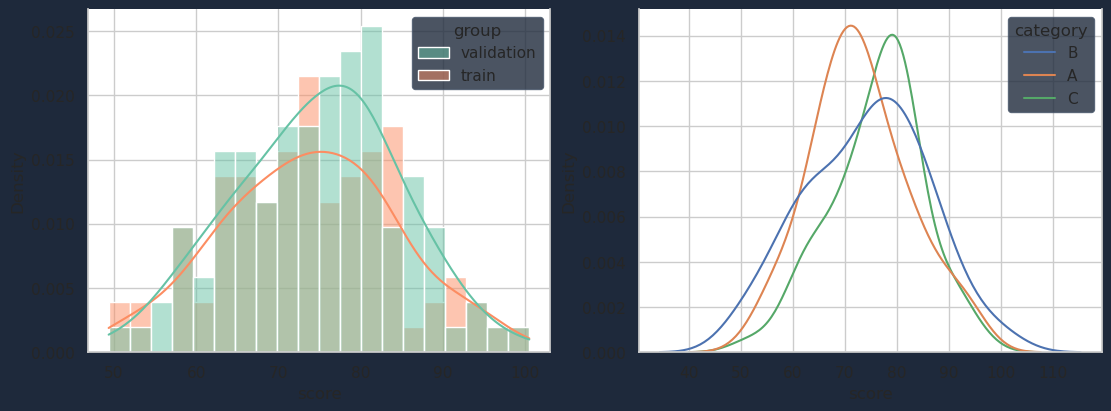

In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
sns.histplot(
    data=df, x="score",           # data/x: source DataFrame and numeric column
    hue="group",                  # hue: split distributions by category
    weights=None,                 # weights: optional contribution per row
    stat="density",               # stat: count, frequency, probability, percent, density
    bins=20,                      # bins: number or boundaries
    binwidth=None,                # binwidth: explicit width; overrides bins when provided
    binrange=None,                # binrange: lower/upper bin limits
    discrete=False,               # discrete=True centers bars on discrete values
    cumulative=False,             # cumulative=True accumulates histogram
    common_bins=True,             # common_bins: share bin boundaries among hue subsets
    common_norm=True,             # common_norm: normalize across all subsets together
    multiple="layer",             # multiple: layer, dodge, stack, fill
    element="bars",               # element: bars, step, poly
    fill=True,                    # fill: fill bars/curves
    shrink=1,                    # shrink: bar width multiplier
    kde=True,                    # kde: overlay kernel density estimate
    line_kws={"linewidth":1.5},   # line_kws: styling for fitted KDE line
    palette="Set2", ax=axes[0]
)
sns.kdeplot(
    data=df, x="score", y=None,   # x/y: one variable for 1D KDE; both for 2D KDE
    hue="category",               # hue: separate density by category
    weights=None,                 # weights: optional observation weights
    palette="deep",               # palette: hue colors
    multiple="layer",             # multiple: layer, stack, fill
    common_norm=True,             # common_norm: normalize across groups jointly
    common_grid=False,            # common_grid: use one evaluation grid across hue groups
    cumulative=False,             # cumulative: plot cumulative density
    bw_method="scott",            # bw_method: KDE bandwidth rule/scalar
    bw_adjust=1,                  # bw_adjust: bandwidth multiplier
    warn_singular=True,           # warn_singular: warn when variance is zero
    log_scale=None,               # log_scale: transform axes to log scale
    levels=10,                    # levels: 2D contour levels; harmless for 1D
    thresh=0.05,                  # thresh: lowest 2D iso-proportion displayed
    gridsize=200,                 # gridsize: evaluation resolution
    cut=3,                       # cut: extend grid by bandwidth multiples
    clip=None,                   # clip: restrict density evaluation range
    legend=True, cbar=False, fill=False, ax=axes[1]
    # legend: show legend; cbar: add colorbar for 2D KDE; fill: fill density area
)
plt.show()


## 6. ecdfplot and rugplot


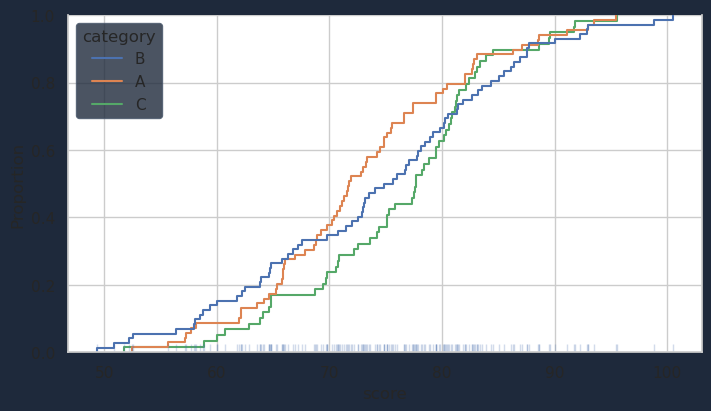

In [7]:
fig,ax=plt.subplots(figsize=(7,4),layout="constrained")
sns.ecdfplot(
    data=df, x="score",           # data/x: source and numeric variable
    hue="category",               # hue: separate ECDF per category
    weights=None,                 # weights: optional row weights
    stat="proportion",            # stat: proportion, percent, count
    complementary=False,         # complementary=True plots 1-ECDF
    palette="deep", legend=True, ax=ax
)
sns.rugplot(
    data=df, x="score", y=None,   # x/y: variable whose observations are marked along an axis
    hue=None,                     # hue: optional grouping variable
    height=0.025,                 # height: tick length as fraction of axes
    expand_margins=True,          # expand_margins: make room for rug marks
    palette=None, legend=False, ax=ax, alpha=.25
)
plt.show()


## 7. countplot and barplot


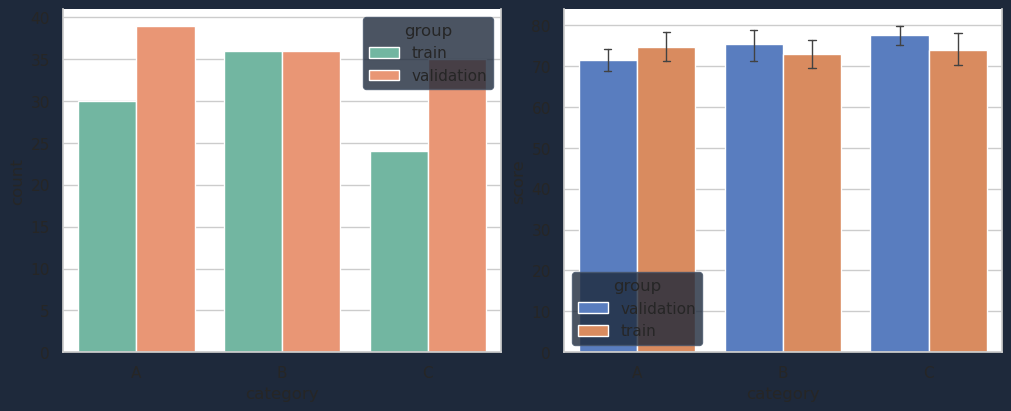

In [8]:
fig,axes=plt.subplots(1,2,figsize=(10,4),layout="constrained")
sns.countplot(
    data=df, x="category", y=None, # use one of x or y for category counts
    hue="group",                   # hue: subdivide each category
    order=["A","B","C"],         # order: category display order
    hue_order=["train","validation"], # hue_order: hue level order
    orient="v",                    # orient: vertical or horizontal
    color=None, palette="Set2",   # color: one color; palette: mapping for hue
    saturation=.75,               # saturation: color saturation multiplier
    fill=True,                    # fill: filled bars when True
    hue_norm=None, stat="count",  # hue_norm: numeric hue mapping; stat: count/percent/proportion
    width=.8, dodge="auto", gap=0,# width: total group width; dodge: separate hue bars; gap: spacing
    log_scale=None, native_scale=False, formatter=None,
    # log_scale: logarithmic axis; native_scale: retain numeric category positions; formatter: label conversion
    legend="auto", ax=axes[0]
)
sns.barplot(
    data=df, x="category", y="score", # x category and numeric y
    hue="group", estimator="mean",     # estimator: summary function
    errorbar=("ci",95), n_boot=1000, seed=42,
    # errorbar: uncertainty method; n_boot: bootstrap count; seed: reproducibility
    units=None, weights=None, order=["A","B","C"], hue_order=None,
    orient="v", color=None, palette="muted", saturation=.75,
    fill=True, hue_norm=None, width=.8, dodge="auto", gap=0,
    log_scale=None, native_scale=False, formatter=None,
    capsize=.1, err_kws={"linewidth":1}, ci="deprecated", legend="auto", ax=axes[1]
    # capsize: error cap width; err_kws: error-bar style; ci is legacy/deprecated compatibility
)
plt.show()


## 8. boxplot, violinplot, stripplot, and swarmplot


In [9]:
fig,axes=plt.subplots(2,2,figsize=(11,8),layout="constrained")
sns.boxplot(data=df,x="category",y="score",hue=None,order=["A","B","C"],hue_order=None,
            orient="v",color="skyblue",palette=None,saturation=.75,fill=True,dodge="auto",
            width=.8,gap=0,whis=1.5,linecolor="black",linewidth=1,fliersize=4,
            hue_norm=None,native_scale=False,log_scale=None,formatter=None,legend="auto",ax=axes[0,0])
# whis: whisker reach in IQR units; fliersize: outlier marker size; linecolor/linewidth: outlines

sns.violinplot(data=df,x="category",y="score",hue=None,order=["A","B","C"],hue_order=None,
               bw_method="scott",bw_adjust=1,cut=2,density_norm="area",common_norm=False,
               gridsize=100,width=.8,inner="box",split=False,dodge="auto",gap=0,
               linewidth=1,linecolor="auto",palette="pastel",saturation=.75,fill=True,
               inner_kws=None,hue_norm=None,legend="auto",scale="deprecated",scale_hue="deprecated",
               gridsize_legacy=None,ax=axes[0,1])
# cut: extension beyond data; density_norm: area/count/width; inner: internal summary; split: split hues

sns.stripplot(data=df,x="category",y="score",hue="group",order=["A","B","C"],hue_order=None,
              jitter=.2,dodge=True,orient="v",color=None,palette="Set2",size=4,edgecolor="gray",
              linewidth=.3,hue_norm=None,log_scale=None,native_scale=False,formatter=None,
              legend="brief",ax=axes[1,0],alpha=.65)
# jitter: random categorical-axis displacement; dodge: separate hue groups; size: marker size

sns.swarmplot(data=df.sample(n=80,random_state=1),x="category",y="score",hue=None,
              order=["A","B","C"],hue_order=None,dodge=False,orient="v",color="teal",
              palette=None,size=4,edgecolor="gray",linewidth=.3,hue_norm=None,
              log_scale=None,native_scale=False,formatter=None,legend="auto",warn_thresh=.05,
              ax=axes[1,1])
# warn_thresh: warn when a high proportion of points cannot be placed without overlap
plt.show()


<exec>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<exec>:8: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='deprecated'` for the same effect.
<exec>:8: FutureWarning: 

The `scale_hue` parameter has been replaced and will be removed in v0.15.0. Pass `common_norm=False` for the same effect.
Traceback (most recent call last):
  File "<exec>", line 8, in <module>
ValueError: The value for `density_norm` must be one of ['area', 'count', 'width'], but 'deprecated' was passed.


## 9. pointplot


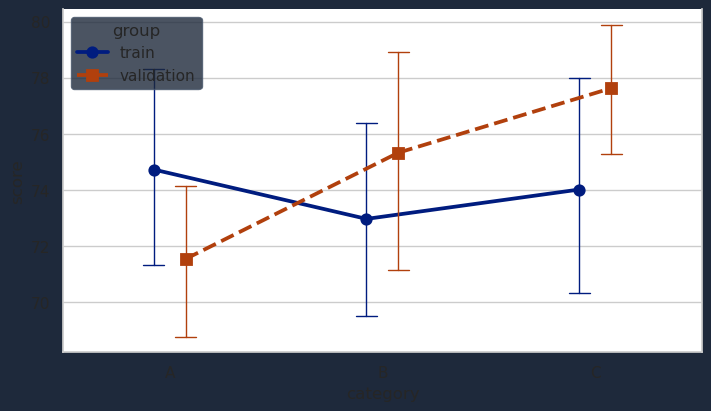

In [10]:
fig,ax=plt.subplots(figsize=(7,4),layout="constrained")
sns.pointplot(
    data=df, x="category", y="score", hue="group",
    order=["A","B","C"], hue_order=["train","validation"],
    estimator="mean", errorbar=("ci",95), n_boot=1000, seed=42,
    units=None, weights=None, color=None, palette="dark", hue_norm=None,
    markers=["o","s"], linestyles=["-","--"], dodge=.15,
    # markers: marker per hue; linestyles: line pattern per hue; dodge: horizontal separation
    log_scale=None, native_scale=False, orient="v", capsize=.1,
    formatter=None, legend="auto", err_kws={"linewidth":1}, ci="deprecated", ax=ax
)
plt.show()


## 10. Regression plots


In [11]:
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
sns.regplot(
    data=df, x="feature", y="target", # variables and source
    x_estimator=None,              # x_estimator: summarize y at unique/discrete x values
    x_bins=None,                   # x_bins: bin x before plotting estimates
    x_ci="ci",                    # x_ci: uncertainty for binned x estimates
    scatter=True, fit_reg=True,    # scatter: show observations; fit_reg: fit regression line
    ci=95, n_boot=1000, units=None, seed=42,
    order=1, logistic=False, lowess=False, robust=False,
    # order: polynomial degree; logistic: logistic fit; lowess: local smooth; robust: robust regression
    logx=False, x_partial=None, y_partial=None,
    # logx: fit y~log(x); x_partial/y_partial: regress out nuisance variables
    truncate=True, dropna=True, x_jitter=None, y_jitter=None,
    # truncate: line within data range; dropna: remove missing; jitter: plotting-only random noise
    label="Linear fit", color="navy", marker="o",
    scatter_kws={"alpha":.4}, line_kws={"linewidth":2}, ax=axes[0]
)

sns.residplot(
    data=df, x="feature", y="target", x_partial=None, y_partial=None,
    lowess=True, order=1, robust=False, dropna=True, label=None,
    color="purple", scatter_kws={"alpha":.4}, line_kws={"color":"black"}, ax=axes[1]
)
axes[1].set_title("Residual plot"); plt.show()


Traceback (most recent call last):
  File "<exec>", line 19, in <module>
RuntimeError: `lowess=True` requires statsmodels, an optional dependency, to be installed.


## 11. Heatmap and correlations


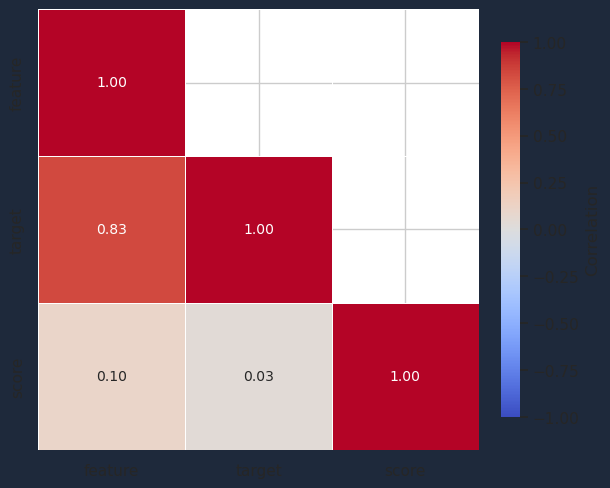

In [12]:
corr=df[["feature","target","score"]].corr(method="pearson",min_periods=1,numeric_only=False)
# method: pearson/kendall/spearman/callable; min_periods: required valid pairs; numeric_only: column filtering
fig,ax=plt.subplots(figsize=(6,5),layout="constrained")
sns.heatmap(
    data=corr,                    # data: rectangular 2D dataset
    vmin=-1, vmax=1, center=0,    # color limits and center value
    cmap="coolwarm",              # cmap: color mapping
    robust=False,                # robust=True uses robust quantiles when limits absent
    annot=True,                  # annot=True writes values in cells
    fmt=".2f",                   # fmt: annotation number format
    annot_kws={"fontsize":10},    # annot_kws: text properties
    linewidths=.5, linecolor="white", # cell boundary width/color
    cbar=True,                   # cbar: display colorbar
    cbar_kws={"shrink":.8,"label":"Correlation"}, # cbar_kws: colorbar settings
    cbar_ax=None,                # cbar_ax: separate axes for colorbar
    square=True,                 # square=True makes cells square
    xticklabels="auto", yticklabels="auto", # tick label selection/frequency
    mask=np.triu(np.ones_like(corr,dtype=bool),k=1), # mask: True cells are hidden
    ax=ax
)
plt.show()


## 12. Pairplot and PairGrid


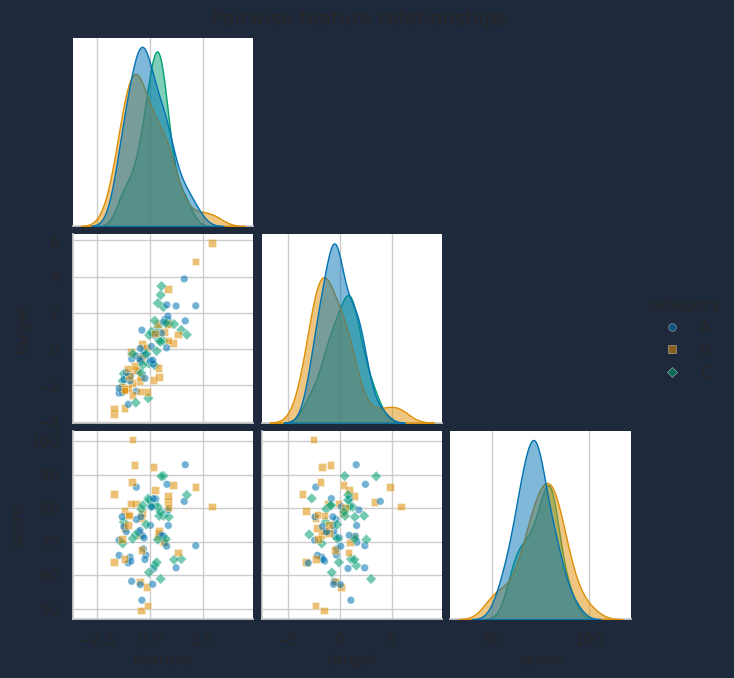

In [13]:
pair = sns.pairplot(
    data=df.sample(n=100,random_state=42), # data: tidy DataFrame
    hue="category",               # hue: color by category
    hue_order=["A","B","C"],     # hue_order: explicit level order
    palette="colorblind",         # palette: hue colors
    vars=["feature","target","score"], # vars: variables shown on both dimensions
    x_vars=None, y_vars=None,     # x_vars/y_vars: asymmetric variable selections
    kind="scatter",               # kind: off-diagonal plot type: scatter, kde, hist, reg
    diag_kind="auto",             # diag_kind: auto, hist, kde, or None
    markers=["o","s","D"],       # markers: marker per hue level
    height=2.2,                   # height: height of each facet in inches
    aspect=1,                     # aspect: width/height ratio of each facet
    corner=True,                 # corner=True hides upper triangle
    dropna=False,                # dropna: remove missing rows before plotting
    plot_kws={"alpha":.55,"s":30}, # plot_kws: off-diagonal plot arguments
    diag_kws={"alpha":.5},        # diag_kws: diagonal plot arguments
    grid_kws={"diag_sharey":False} # grid_kws: PairGrid constructor settings
)
pair.fig.suptitle("Pairwise feature relationships",y=1.02)
plt.show()


## 13. relplot and catplot figure-level APIs


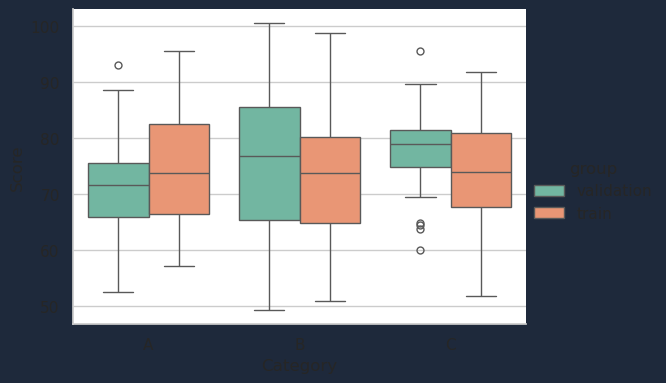

In [14]:
g=sns.relplot(
    data=df,x="feature",y="target",hue="category",size=None,style="group",
    row=None,col="group",col_wrap=None,row_order=None,col_order=["train","validation"],
    palette="deep",hue_order=None,hue_norm=None,sizes=None,size_order=None,size_norm=None,
    markers=True,dashes=True,style_order=None,legend="auto",kind="scatter",
    # row/col: facet variables; col_wrap: columns before wrapping; kind: scatter or line
    height=3,aspect=1.1,facet_kws={"sharex":True,"sharey":True},alpha=.6
)
g.set_axis_labels("Feature","Target"); plt.show()

g=sns.catplot(
    data=df,x="category",y="score",hue="group",row=None,col=None,col_wrap=None,
    estimator="mean",errorbar=("ci",95),n_boot=1000,seed=42,units=None,weights=None,
    order=["A","B","C"],hue_order=None,row_order=None,col_order=None,kind="box",
    height=4,aspect=1.4,orient="v",color=None,palette="Set2",hue_norm=None,
    legend="auto",legend_out=True,sharex=True,sharey=True,margin_titles=False,
    facet_kws=None,native_scale=False,formatter=None
)
# kind: strip, swarm, box, violin, boxen, point, bar, or count
# legend_out=True places legend outside figure; margin_titles controls facet title placement
g.set_axis_labels("Category","Score"); plt.show()


## 14. Jointplot and clustermap


In [15]:
g=sns.jointplot(
    data=df,x="feature",y="target",hue=None,
    kind="reg",                   # kind: scatter, kde, hist, hex, reg, or resid
    height=6,ratio=5,space=.2,    # height: figure size; ratio: joint/marginal ratio; space: gap
    dropna=False,xlim=None,ylim=None,color="teal",palette=None,hue_order=None,hue_norm=None,
    marginal_ticks=False,joint_kws={"scatter_kws":{"alpha":.35}},marginal_kws={"bins":20}
)
plt.show()

matrix=df.pivot_table(index="category",columns="group",values="score",aggfunc="mean")
g=sns.clustermap(
    data=matrix,                   # data: rectangular matrix
    pivot_kws=None,               # pivot_kws: pivot instructions when data is long-form
    method="average",             # method: linkage method
    metric="euclidean",           # metric: distance metric
    z_score=None, standard_scale=None, # optional row/column standardization
    figsize=(6,5),cbar_kws={"label":"Mean score"},row_cluster=True,col_cluster=True,
    row_linkage=None,col_linkage=None,row_colors=None,col_colors=None,
    mask=None,dendrogram_ratio=.2,colors_ratio=.03,cbar_pos=(.02,.8,.05,.18),
    tree_kws={"linewidths":1}
)
plt.show()


Traceback (most recent call last):
  File "<exec>", line 11, in <module>
RuntimeError: clustermap requires scipy to be available


## 15. Combining Seaborn with Matplotlib control


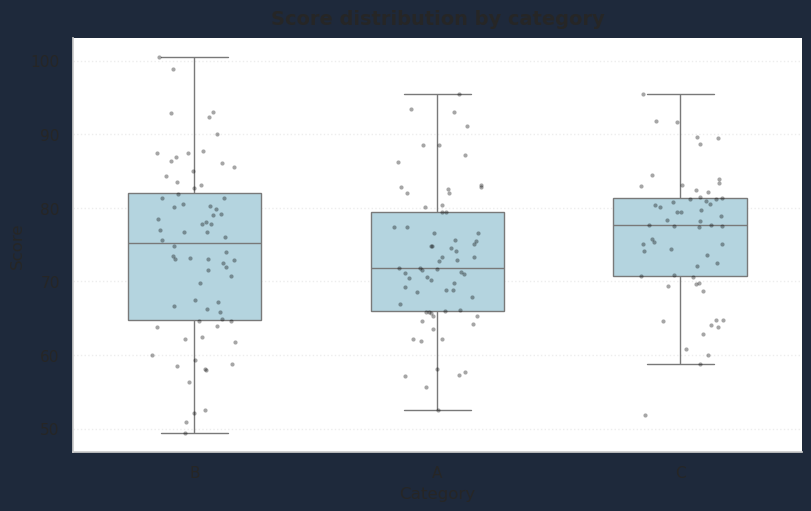

In [16]:
fig,ax=plt.subplots(figsize=(8,5),layout="constrained")
sns.boxplot(data=df,x="category",y="score",color="lightblue",width=.55,showfliers=False,ax=ax)
sns.stripplot(data=df,x="category",y="score",color="black",alpha=.35,jitter=.18,size=3,ax=ax)
ax.set_title("Score distribution by category",fontsize=14,fontweight="bold",pad=10)
ax.set_xlabel("Category"); ax.set_ylabel("Score")
ax.grid(axis="y",linestyle=":",alpha=.35)
sns.despine(fig=fig,ax=ax,top=True,right=True,left=False,bottom=False,offset=None,trim=False)
# fig/ax: target figure and axes; top/right/left/bottom: spines removed when True
# offset: outward spine offset; trim: restrict spines to tick range
plt.show()


## Final Seaborn checklist

Master semantic mappings (`x`, `y`, `hue`, `size`, `style`), distribution plots, categorical plots, regression/residual analysis, heatmaps, pairwise relationships, faceting, and Matplotlib finishing.

Use **axes-level functions** such as `scatterplot` when embedding in a custom subplot layout. Use **figure-level functions** such as `relplot`, `catplot`, `pairplot`, and `jointplot` when Seaborn should manage the complete multi-panel figure.
